# Gaussian Mixture Models (GMM) — From Scratch + Comparison with k-means + Digits Generation

This notebook combines:
- **MML-book GMM tutorial & solution** — theoretical EM derivation and from-scratch implementation
- **Python Data Science Handbook** (Jake VanderPlas) — visual exploration, k-means vs GMM comparison, and generative modeling

We will:
1. Implement GMM using EM algorithm **from scratch**
2. Fit it to a **non-spherical 2D dataset** for better visualization
3. Compare to **k-means**
4. Apply GMMs for **digit clustering and generation**


# Практика 6: Gaussian Mixture Models (GMM) та EM-алгоритм

**Тема:** Кластеризація даних та генеративні моделі за допомогою гауссівських сумішей.
**Мета роботи:** Реалізувати алгоритм очікування-максимізації (Expectation-Maximization) для GMM "з нуля" та порівняти його з класичним k-means, а також використати GMM для генерації нових даних (синтетичних цифр).

**Контроль машинних похибок (Floating Point Issues):**
У цій роботі ми стикаємося з проблемою математичного недоповнення (underflow). Ймовірності належності точок до кластерів є надзвичайно малими числами. Якщо їх просто перемножувати, комп'ютер швидко округлить результат до `0.0`.
Щоб алгоритм не впав, ми застосуємо два рішення:
1. Перехід у логарифмічний простір: використання функції `logsumexp` для стабільного додавання експонент.
2. Регуляризація коваріації: додавання мікроскопічного значення `reg_covar` до діагоналі коваріаційних матриць, щоб запобігти їхньому виродженню (машинному нулю на діагоналі).

## Learning goals
After this tutorial you should be able to:
- Understand the EM algorithm for Gaussian Mixture Models
- Implement E-step and M-step manually
- Visualize how GMM generalizes k-means
- Use GMM to model digits as a generative model


In [3]:
# PACKAGE: DO NOT EDIT
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

plt.rcParams['figure.figsize'] = (6, 4)


## 1. Synthetic 2D Dataset with Non-Spherical Clusters

We'll create a toy dataset and apply a random linear transformation to make clusters **elongated and rotated**.  
This helps visualize the difference between **k-means** (spherical clusters) and **GMM** (elliptical clusters).


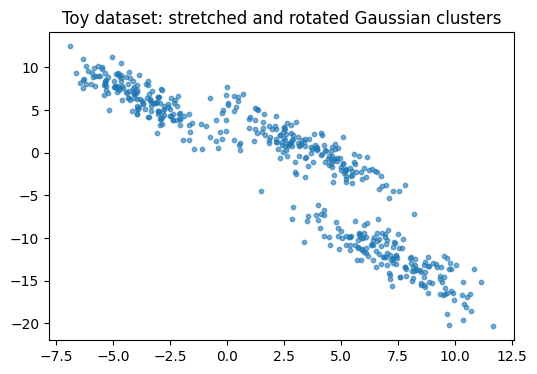

In [4]:
# Create isotropic blobs
rng = np.random.default_rng(13)
X, y_true = make_blobs(
    n_samples=500,
    centers=[(-2, 0), (0, 4), (4, 0)],
    cluster_std=[0.8, 0.9, 1.0],
    random_state=0
)

# Stretch and rotate using random matrix
X_stretched = np.dot(X, rng.standard_normal((2, 2)))

plt.scatter(X_stretched[:, 0], X_stretched[:, 1], s=10, alpha=0.6)
plt.title("Toy dataset: stretched and rotated Gaussian clusters")
plt.show()


In [5]:
def init_gmm_params(X, n_components, random_state=0):
    """Initialize means, covariances, and weights."""
    # TODO: initialize GMM parameters (means from data, identity covariances, uniform weights)

    rng = np.random.default_rng(random_state)
    n_samples, n_features = X.shape

    # щоб ініціалізувати центри випадково обираємо n_components точок з датасету
    indices = rng.choice(n_samples, n_components, replace=False)
    means = X[indices].copy()

    #  одиничні матриці для кожної компоненти(коваріації)
    covs = np.array([np.eye(n_features) for _ in range(n_components)])

    # Ініціалізація ваг, рівномірний розподіл (сума дорівнює 1)
    pi = np.ones(n_components) / n_components

    return pi, means, covs

In [6]:
def log_gaussian_pdf(X, mean, cov):
    """Compute log N(x|mean,cov) for each x."""
    # TODO: use np.linalg.slogdet or np.linalg.cholesky for stability
    n_samples, n_features = X.shape

    #FIX slogdet для уникнення overflow/underflow
    sign, logdet = np.linalg.slogdet(cov)
    if sign <= 0:
        raise ValueError("Covariance matrix must be positive definite")

    inv_cov = np.linalg.inv(cov)
    diff = X - mean

    # векторизоване обчислення відстані Махаланобіса за формулою (x-mu)^T * Sigma^-1 * (x-mu)
    mahalanobis = np.sum(np.dot(diff, inv_cov) * diff, axis=1)

    # формула логарифма щільності нормального розподілу
    log_pdf = -0.5 * (n_features * np.log(2 * np.pi) + logdet + mahalanobis)

    return log_pdf


In [7]:
from scipy.special import logsumexp
def e_step(X, pi, means, covs):
    """E-step: compute responsibilities and the current log-likelihood.

    Returns:
        gamma: array (n_samples, n_components), rows summing to 1.
        log_likelihood: float, sum over samples of log p(x_n).
    """
    # TODO: compute weighted log-probabilities, normalize using log-sum-exp

    n_samples = X.shape[0]
    n_components = len(pi)
    weighted_log_probs = np.zeros((n_samples, n_components))

    # обчислюємо логарифм спільної ймовірності P(Z) * P(X|Z)
    for k in range(n_components):
        weighted_log_probs[:, k] = np.log(pi[k]) + log_gaussian_pdf(X, means[k], covs[k])

    # FIX: logsumexp для стабільного сумування логарифмів
    log_prob_norm = logsumexp(weighted_log_probs, axis=1)

    # Відповідальності (responsibilities) gamma = P(Z|X)
    log_gamma = weighted_log_probs - log_prob_norm[:, np.newaxis]
    gamma = np.exp(log_gamma)

    # Сумарна логарифмічна правдоподібність для моніторингу збіжності
    log_likelihood = np.sum(log_prob_norm)

    return gamma, log_likelihood

In [8]:
def m_step(X, gamma, reg_covar=1e-6):
    """M-step: update pi, means, and covariances."""
    # TODO: implement mean/cov updates
    n_samples, n_features = X.shape
    n_components = gamma.shape[1]

    # Ефективна кількість точок для кожної компоненти
    N_k = gamma.sum(axis=0)

    # Оновлення ваг
    pi_new = N_k / n_samples

    # Оновлення центрів (середніх)
    means_new = np.dot(gamma.T, X) / N_k[:, np.newaxis]

    # Оновлення коваріацій
    covs_new = np.zeros((n_components, n_features, n_features))
    for k in range(n_components):
        diff = X - means_new[k]
        # Зважена коваріація
        covs_new[k] = np.dot((gamma[:, k, np.newaxis] * diff).T, diff) / N_k[k]
        # FLOATING POINT FIX: Регуляризатор на діагоналі проти машинного нуля
        covs_new[k] += reg_covar * np.eye(n_features)

    return pi_new, means_new, covs_new

In [9]:
# SELF-CHECK - run this once init_gmm_params, log_gaussian_pdf, e_step and m_step
# are implemented (before writing the EM loop).
pi_chk, means_chk, covs_chk = init_gmm_params(X_stretched, 3, random_state=0)
gamma_chk, ll_chk = e_step(X_stretched, pi_chk, means_chk, covs_chk)

assert gamma_chk.shape == (X_stretched.shape[0], 3), "responsibilities are (n_samples, n_components)"
assert np.allclose(gamma_chk.sum(axis=1), 1.0), "each point's responsibilities must sum to 1"
assert np.all(gamma_chk >= -1e-12), "responsibilities are probabilities"
assert np.ndim(ll_chk) == 0, "e_step must also return the scalar log-likelihood"

pi_new, means_new, covs_new = m_step(X_stretched, gamma_chk)
assert np.isclose(pi_new.sum(), 1.0), "mixture weights must sum to 1"
assert np.all(np.linalg.eigvalsh(covs_new) > 0), "every covariance must stay positive definite"

print("GMM self-check passed")

GMM self-check passed


In [12]:
def gmm_em(X, n_components, max_iter=100, tol=1e-4, random_state=0):
    """Run EM algorithm for GMM."""
    # TODO: combine steps into EM loop (initialize → alternate E and M → stop on convergence)
    pi, means, covs = init_gmm_params(X, n_components, random_state)
    ll_history = []

    for i in range(max_iter):
        # Expectation step
        gamma, ll = e_step(X, pi, means, covs)
        ll_history.append(ll)

        # Перевірка збіжності алгоритму
        if i > 0 and (ll - ll_history[-2]) < tol:
            break

        # Maximization step
        pi, means, covs = m_step(X, gamma)

    return pi, means, covs, ll_history

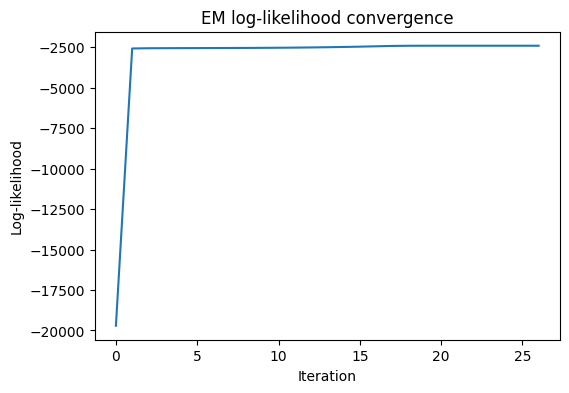

In [13]:
# Fit your GMM from scratch on the stretched dataset
K = 3
pi_hat, means_hat, covs_hat, ll = gmm_em(X_stretched, n_components=K, random_state=0)

plt.plot(ll)
plt.title("EM log-likelihood convergence")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()


## 2. Compare GMM vs k-means

Use your GMM implementation and sklearn's k-means to see how they differ on the **stretched data**.


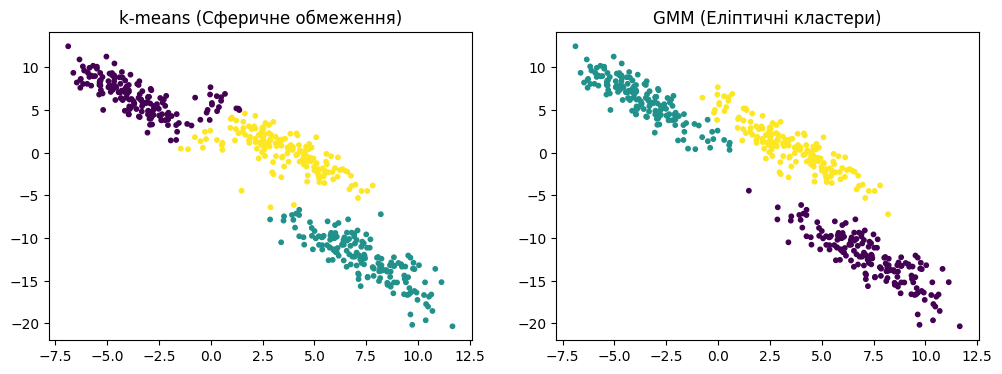

In [14]:
# TODO: fit k-means (n_clusters=3) and plot vs GMM responsibilities
# Навчання k-means
kmeans = KMeans(n_clusters=3, random_state=0).fit(X_stretched)
y_kmeans = kmeans.predict(X_stretched)

# Навчання нашого GMM (вже натреновано вище, просто дістаємо передбачення)
gamma_hat, _ = e_step(X_stretched, pi_hat, means_hat, covs_hat)
y_gmm = gamma_hat.argmax(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(X_stretched[:, 0], X_stretched[:, 1], c=y_kmeans, s=10, cmap='viridis')
ax1.set_title("k-means (Сферичне обмеження)")

ax2.scatter(X_stretched[:, 0], X_stretched[:, 1], c=y_gmm, s=10, cmap='viridis')
ax2.set_title("GMM (Еліптичні кластери)")

plt.show()


## 3. GMM on Digits Dataset

Now let's move from 2D toy data to a higher-dimensional example.

We'll use the `digits` dataset to:
- fit GMMs to 10 components
- visualize learned component means as prototypical digits
- sample new synthetic digits


In [15]:
digits = load_digits()
X_digits = digits.data
images = digits.images
print("Digits shape:", X_digits.shape)


Digits shape: (1797, 64)


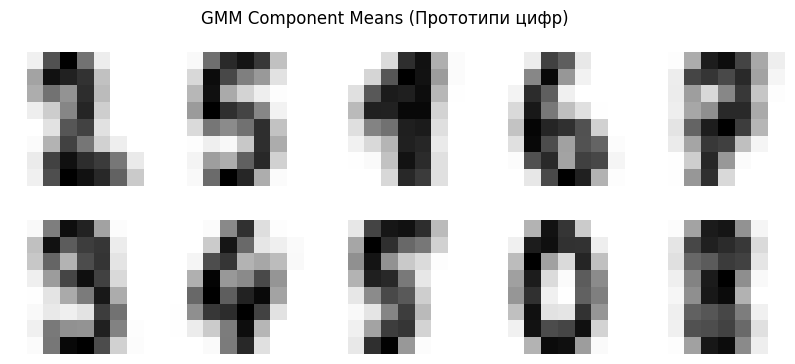

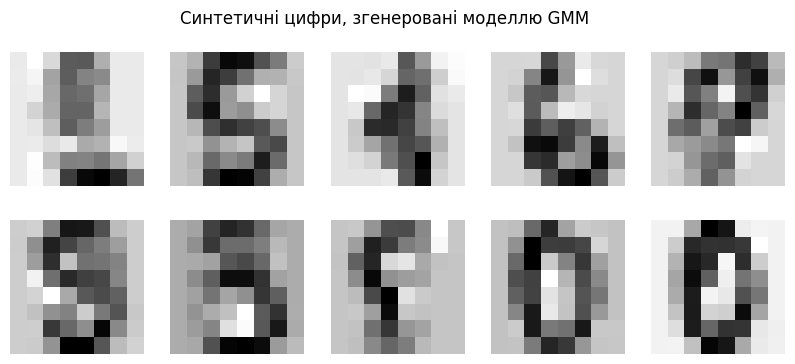

In [16]:
# TODO: Fit GaussianMixture from sklearn and visualize its means and generated samples
# Тренування моделі GaussianMixture
gmm_digits = GaussianMixture(n_components=10, covariance_type='full', random_state=0)
gmm_digits.fit(X_digits)

# Візуалізація центрів кластерів (компонент) як прототипів цифр
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(gmm_digits.means_[i].reshape(8, 8), cmap='binary')
    ax.axis('off')
fig.suptitle("GMM Component Means (Прототипи цифр)")
plt.show()

# Генерація нових синтетичних цифр із вивченого розподілу
X_new, _ = gmm_digits.sample(10)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_new[i].reshape(8, 8), cmap='binary')
    ax.axis('off')
fig.suptitle("Синтетичні цифри, згенеровані моделлю GMM")
plt.show()

## 4. Reflection

In your own words:
- What is the main difference between k-means and GMM?
- Why does GMM handle elongated clusters better?
- How does GMM act as a **generative** model?




**1. Головна відмінність між k-means та GMM:**
кожна точка чітко закріплюється за одним конкретним кластером на основі звичайної евклідової відстані. GMM працює гнучкіше, використовуючи «м'яку» (soft) кластеризацію. Замість однозначного вибору вона рахує ймовірність, з якою точка може належати до кожного з кластерів, причому оцінює не лише відстань, а й геометрію самої групи. Фактично, k-means є спрощеним окремим випадком GMM, де коваріаційні матриці за замовчуванням вважаються одиничними.

**2. Чому GMM краще працює з видовженими кластерами:**
у GMM є можливість налаштувати матрицю коваріації (параметр covariance_type='full'). Вона допомагає врахувати розкид даних у різних напрямках та взаємозв'язок між фічами. І через це кластери можуть підлаштовуватися під будь-які еліптичні форми з різним розміром і нахилом. Алгоритм k-means натомість шукає лише правильні круглі сфери (ізотропна коваріація), тому він просто ламає і неправильно розрізає витягнуті хмари даних.

**3. Як GMM виступає в ролі генеративної моделі:**
 дискримінативні алгоритми вміють лише проводити розділяційні лінії між класами, а GMM намагається розібратися у самій структурі даних. Модель описує реальний розподіл \(P(X)\) як суміш кількох гаусівських розподілів. Маючи готову функцію щільності ймовірності, ми можемо робити з неї випадкові вибірки — наприклад, через метод Монте-Карло або звичайною функцією .sample(). Це дозволяє генерувати абсолютно нові, штучні екземпляри даних (наприклад, синтетичні зображення цифр), які за своїми статистичними властивостями дуже схожі на справжні.

Практика 6 (Шпаргалка)

У цій роботі ми реалізували EM-алгоритм для моделі гауссівських сумішей (GMM), подолавши проблеми машинної арифметики. На що звернути увагу:

• Проблема недоповнення (Underflow) та трюк logsumexp:
коли ми працюємо з великою кількістю ознак (як-от 64 пікселі у датасеті Digits), ймовірність того, що точка потрапить у конкретний кластер, стає мікроскопічною — щось типу \(10^{-50}\). Комп'ютер не вміє адекватно тримати в пам'яті такі дрібні числа типу float і просто округлює їх до чистого нуля. Щоб усе не зламалося, ми перевели всі розрахунки на E-кроці у логарифми. А коли треба було додати ці експоненти для нормалізації, ми використали математичний трюк logsumexp: він виносить найбільше значення за дужки, завдяки чому програма не перетворює цифри на нулі чи нескінченність.

---


• Виродження коваріаційних матриць (Singular Covariance):
під час оновлення матриць на M-кроці може виникнути халепа: якщо в кластері опинилося замало точок або вони вишикувалися майже в одну лінію, визначник матриці коваріації наближається до нуля. Через це комп'ютер не може знайти обернену матрицю для формули Гауса, і код просто вилітає з помилкою LinAlgError. Ми вирішили це через регуляризацію: додали крихітне число reg_covar (десь \(10^{-6}\)) по діагоналі кожної матриці. Це додає мізерний штучний розкид у всіх напрямках, зате гарантує, що матриця завжди нормально обертатиметься.

---


• Hard vs Soft Clustering (Чому GMM гнучкіший за k-means):
K-means діє дуже прямолінійно й "жорстко": він вважає, що всі кластери мають бути ідеально круглими (сферичними), а кожна точка може належати лише до однієї групи на всі 100%. GMM працює набагато розумніше — через "м'яку" кластеризацію. Ми рахуємо відсоткову ймовірність (вагу \(\gamma \)) приналежності точки до кожного кластера. До того ж завдяки повній матриці коваріації модель розуміє, що кластери в реальному житті можуть бути витягнутими, як еліпси, або повернутими під будь-яким кутом.

---


• Генеративна потужність моделі:
суть GMM не в тому, щоб просто розкидати картинки з цифрами по купках. Модель буквально вивчає саму природу та структуру даних, будуючи загальну функцію розподілу \(P(X)\). Саме тому, коли ми викликаємо метод .sample(), алгоритм може згенерувати абсолютно нові зображення цифр, яких ніколи не було в початковому датасеті. Він просто бере випадкові координати з уже вивчених багатовимірних гаусіанів.
